 ### Threshold-only architecture
 Using Classifier's full probability distribution over the 10 distortion classes, on both the validation set and the augmented test set

In [1]:
# Colab setup — mount Drive and install packages
try:
    from google.colab import drive
    drive.mount('/content/drive')
    IS_COLAB = True
except ImportError:
    IS_COLAB = False

if IS_COLAB:
    %pip install -q transformers datasets accelerate

Mounted at /content/drive


In [2]:
import torch
import numpy as np
import pandas as pd
from pathlib import Path
from torch.nn.functional import softmax
from transformers import AutoTokenizer, AutoModelForSequenceClassification

# === EDIT THESE PATHS ===
PROJECT_ROOT = Path("/content/drive/MyDrive/thesis_stage2")
RESULTS_DIR   = PROJECT_ROOT / "results"

# Path to your existing α=0.3 type classifier checkpoint folder
TYPE_CHECKPOINT = PROJECT_ROOT / "models" / "patternreframe_soft30"

# Augmented val and test (with the No Distortion records included)
VAL_CSV  = PROJECT_ROOT / "patternreframe_val_aug_v1_rebalanced.csv"
TEST_CSV = PROJECT_ROOT / "patternreframe_test_aug_v1_rebalanced.csv"

# The 10-class label order the type classifier was trained on. MUST match
# the order in the model's id2label config; the script asserts this below.
PATTERNREFRAME_LABELS = [
    "Black-and-white or polarized thinking / All or nothing thinking",
    "Catastrophizing",
    "Discounting the positive",
    "Jumping to conclusions: Fortune-telling",
    "Jumping to conclusions: mind reading",
    "Labeling and mislabeling",
    "Mental filtering",
    "Overgeneralization",
    "Personalization",
    "Should statements",
]

MAX_LEN = 512
BS = 64

# === Load checkpoint ===
print(f"Loading type classifier from {TYPE_CHECKPOINT}")
tokenizer = AutoTokenizer.from_pretrained(TYPE_CHECKPOINT)
model = AutoModelForSequenceClassification.from_pretrained(TYPE_CHECKPOINT)

# Verify the label order matches what we expect
cfg_labels = [model.config.id2label[i] for i in sorted(model.config.id2label, key=int)]
assert cfg_labels == PATTERNREFRAME_LABELS, (
    f"Checkpoint label order mismatch.\nExpected: {PATTERNREFRAME_LABELS}\nFound:    {cfg_labels}"
)
print("Label order verified.")

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model.to(device).eval()

# === Predict probabilities on val and test ===
def predict_probs(csv_path):
    df = pd.read_csv(csv_path)
    df = df.copy()
    df["text"] = df["thought"].astype(str)
    df["true_pattern"] = df["pattern"]
    df["true_label"] = df["pattern"].apply(
        lambda p: -1 if p == "No Distortion" else PATTERNREFRAME_LABELS.index(p)
    )

    all_probs = []
    with torch.no_grad():
        for i in range(0, len(df), BS):
            batch = df["text"].iloc[i:i+BS].tolist()
            enc = tokenizer(batch, truncation=True, max_length=MAX_LEN,
                            padding=True, return_tensors="pt").to(device)
            logits = model(**enc).logits
            all_probs.append(softmax(logits, dim=-1).cpu().numpy())
    probs = np.vstack(all_probs)

    # Attach probability columns
    for i, lbl in enumerate(PATTERNREFRAME_LABELS):
        df[f"prob_{i}"] = probs[:, i]
    df["max_prob"] = probs.max(axis=1)
    df["argmax_idx"] = probs.argmax(axis=1)
    df["argmax_label"] = df["argmax_idx"].map(lambda i: PATTERNREFRAME_LABELS[int(i)])
    return df

val_df  = predict_probs(VAL_CSV)
test_df = predict_probs(TEST_CSV)

print(f"Val:  {len(val_df)} rows ({(val_df['true_pattern']=='No Distortion').sum()} ND)")
print(f"Test: {len(test_df)} rows ({(test_df['true_pattern']=='No Distortion').sum()} ND)")

# Save for later use
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
val_df.to_csv(RESULTS_DIR  / "type_classifier_val_probs.csv",  index=False)
test_df.to_csv(RESULTS_DIR / "type_classifier_test_probs.csv", index=False)
print(f"Saved probability predictions to {RESULTS_DIR}")

Loading type classifier from /content/drive/MyDrive/thesis_stage2/models/patternreframe_soft30


Loading weights:   0%|          | 0/201 [00:01<?, ?it/s]

Label order verified.
Val:  1162 rows (201 ND)
Test: 7488 rows (681 ND)
Saved probability predictions to /content/drive/MyDrive/thesis_stage2/results


Val set: 1162 records (201 ND, 961 distorted)

max_prob on ND records:
  mean   = 0.504
  median = 0.480
  p10/p90 = 0.276 / 0.780

max_prob on distorted records:
  mean   = 0.699
  median = 0.721
  p10/p90 = 0.432 / 0.929

Gap in means: +0.195
(0.20+ = clear separation, 0.05-0.15 = borderline, <0.05 = no signal)


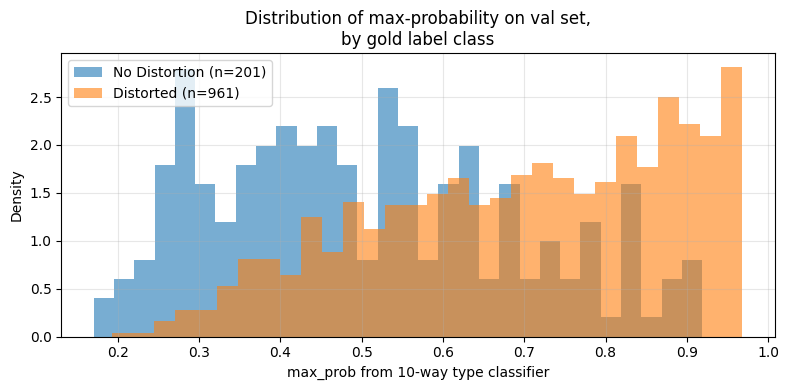

In [3]:
# Quick diagnostic: does max_prob actually separate ND from distorted?
# Run after Cell 1 (which produces val_df with max_prob column).

import matplotlib.pyplot as plt

nd_mask  = val_df["true_pattern"] == "No Distortion"
nd_max   = val_df.loc[nd_mask,  "max_prob"]
dist_max = val_df.loc[~nd_mask, "max_prob"]

print(f"Val set: {len(val_df)} records ({nd_mask.sum()} ND, {(~nd_mask).sum()} distorted)")
print(f"\nmax_prob on ND records:")
print(f"  mean   = {nd_max.mean():.3f}")
print(f"  median = {nd_max.median():.3f}")
print(f"  p10/p90 = {nd_max.quantile(0.10):.3f} / {nd_max.quantile(0.90):.3f}")
print(f"\nmax_prob on distorted records:")
print(f"  mean   = {dist_max.mean():.3f}")
print(f"  median = {dist_max.median():.3f}")
print(f"  p10/p90 = {dist_max.quantile(0.10):.3f} / {dist_max.quantile(0.90):.3f}")
print(f"\nGap in means: {dist_max.mean() - nd_max.mean():+.3f}")
print(f"(0.20+ = clear separation, 0.05-0.15 = borderline, <0.05 = no signal)")

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(nd_max,   bins=30, alpha=0.6, label=f"No Distortion (n={nd_mask.sum()})", density=True)
ax.hist(dist_max, bins=30, alpha=0.6, label=f"Distorted (n={(~nd_mask).sum()})", density=True)
ax.set_xlabel("max_prob from 10-way type classifier")
ax.set_ylabel("Density")
ax.set_title("Distribution of max-probability on val set,\nby gold label class")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

The threshold τ converts the type classifier into an 11-class classifier: predict argmax_label if max_prob ≥ τ, else No Distortion. The question is what value of τ to use.
Three objectives:

1. Maximise weighted F1 on val. This is the standard model-selection criterion. Tends toward lower τ.
2. Maximise macro F1 on val. Weights ND equally with each distortion class. Tends toward higher τ.
3. Match a target ND recall on val. Useful to guarantee at least X% recall on the rare ND class. States explicitly what trade-off the chapter is making.

τ maximising val weighted F1:    0.46 (wF1=0.5491)
τ maximising val macro F1:       0.46 (mF1=0.5634)
τ hitting val ND recall ≥ 80%: 0.68 (NDR=0.816, DR=0.568)


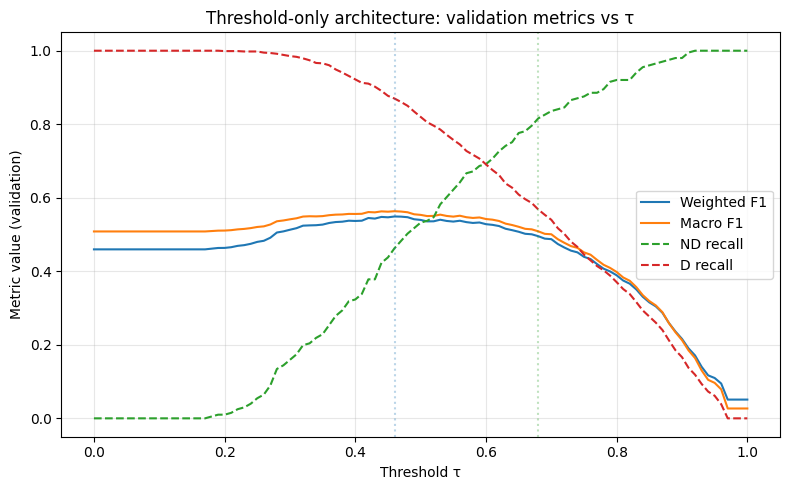

In [4]:
import pandas as pd
import numpy as np
from sklearn.metrics import f1_score, classification_report, confusion_matrix

# Reload from disk so this cell is self-contained
val_df  = pd.read_csv(RESULTS_DIR / "type_classifier_val_probs.csv")
test_df = pd.read_csv(RESULTS_DIR / "type_classifier_test_probs.csv")

ELEVEN_CLASS_LABELS = ["No Distortion"] + PATTERNREFRAME_LABELS


def apply_threshold(df, tau):
    """Return predicted 11-class labels for a given threshold τ."""
    preds = np.where(df["max_prob"].values >= tau,
                     df["argmax_label"].values,
                     "No Distortion")
    return preds


def gold_11class(df):
    return df["true_pattern"].values


def score(df, tau, average):
    preds = apply_threshold(df, tau)
    return f1_score(gold_11class(df), preds, labels=ELEVEN_CLASS_LABELS,
                    average=average, zero_division=0)


def nd_recall(df, tau):
    gold = gold_11class(df)
    preds = apply_threshold(df, tau)
    nd_mask = (gold == "No Distortion")
    return (preds[nd_mask] == "No Distortion").mean()


def d_recall(df, tau):
    gold = gold_11class(df)
    preds = apply_threshold(df, tau)
    d_mask = (gold != "No Distortion")
    return (preds[d_mask] != "No Distortion").mean()


# === Sweep τ on val ===
taus = np.linspace(0.0, 1.0, 101)
sweep = []
for tau in taus:
    sweep.append({
        "tau": tau,
        "val_wf1":  score(val_df, tau, "weighted"),
        "val_mf1":  score(val_df, tau, "macro"),
        "val_nd_recall": nd_recall(val_df, tau),
        "val_d_recall":  d_recall(val_df, tau),
    })
sweep_df = pd.DataFrame(sweep)

# === Best τ under each criterion ===
tau_wf1 = sweep_df.loc[sweep_df["val_wf1"].idxmax(), "tau"]
tau_mf1 = sweep_df.loc[sweep_df["val_mf1"].idxmax(), "tau"]
# τ that hits at least 80% ND recall while maximising distorted recall
target_nd = 0.80
candidates = sweep_df[sweep_df["val_nd_recall"] >= target_nd]
tau_nd80 = candidates.loc[candidates["val_d_recall"].idxmax(), "tau"] if len(candidates) else 1.0

print(f"τ maximising val weighted F1:    {tau_wf1:.2f} (wF1={score(val_df, tau_wf1, 'weighted'):.4f})")
print(f"τ maximising val macro F1:       {tau_mf1:.2f} (mF1={score(val_df, tau_mf1, 'macro'):.4f})")
print(f"τ hitting val ND recall ≥ {target_nd:.0%}: {tau_nd80:.2f} "
      f"(NDR={nd_recall(val_df, tau_nd80):.3f}, DR={d_recall(val_df, tau_nd80):.3f})")

# === Visualise the trade-off ===
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(sweep_df["tau"], sweep_df["val_wf1"],       label="Weighted F1")
ax.plot(sweep_df["tau"], sweep_df["val_mf1"],       label="Macro F1")
ax.plot(sweep_df["tau"], sweep_df["val_nd_recall"], label="ND recall", linestyle="--")
ax.plot(sweep_df["tau"], sweep_df["val_d_recall"],  label="D recall",  linestyle="--")
ax.axvline(tau_wf1, color="C0", alpha=0.3, linestyle=":")
ax.axvline(tau_nd80, color="C2", alpha=0.3, linestyle=":")
ax.set_xlabel("Threshold τ")
ax.set_ylabel("Metric value (validation)")
ax.set_title("Threshold-only architecture: validation metrics vs τ")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(RESULTS_DIR / "threshold_sweep_val.png", dpi=150)
plt.show()

sweep_df.to_csv(RESULTS_DIR / "threshold_sweep_val.csv", index=False)

In [5]:
def full_report(df, tau, name):
    preds = apply_threshold(df, tau)
    gold = gold_11class(df)
    print(f"\n=== Threshold-only @ τ={tau:.2f} — {name} ===")
    print(f"Accuracy:    {(preds == gold).mean():.4f}")
    print(f"Weighted F1: {score(df, tau, 'weighted'):.4f}")
    print(f"Macro F1:    {score(df, tau, 'macro'):.4f}")
    print(f"ND recall:   {nd_recall(df, tau):.4f}")
    print(f"D recall:    {d_recall(df, tau):.4f}")
    print()
    print(classification_report(
        gold, preds, labels=ELEVEN_CLASS_LABELS,
        digits=4, zero_division=0,
    ))

for tau, name in [(tau_wf1, "max val wF1"),
                  (tau_mf1, "max val mF1"),
                  (tau_nd80, f"val ND recall ≥ {target_nd:.0%}")]:
    full_report(test_df, tau, name)

# Save the test predictions for the chosen production τ — typically the
# wF1-maximising one. Adjust this assignment after seeing the numbers.
production_tau = tau_wf1
production_preds = apply_threshold(test_df, production_tau)

threshold_test_df = pd.DataFrame({
    "text":                    test_df["text"],
    "gold_label":              test_df["true_pattern"],
    "threshold_pred_label":    production_preds,
    "threshold_tau":           production_tau,
    "max_prob":                test_df["max_prob"],
    "argmax_label":            test_df["argmax_label"],
})
threshold_test_df.to_csv(
    RESULTS_DIR / "threshold_only_test_predictions.csv", index=False
)
print(f"\nSaved threshold-only test predictions @ τ={production_tau:.2f}")


=== Threshold-only @ τ=0.46 — max val wF1 ===
Accuracy:    0.5597
Weighted F1: 0.5673
Macro F1:    0.5686
ND recall:   0.4376
D recall:    0.8446

                                                                 precision    recall  f1-score   support

                                                  No Distortion     0.2198    0.4376    0.2926       681
Black-and-white or polarized thinking / All or nothing thinking     0.6700    0.4030    0.5033       665
                                                Catastrophizing     0.6440    0.5882    0.6148       726
                                       Discounting the positive     0.6252    0.6931    0.6574       681
                        Jumping to conclusions: Fortune-telling     0.4378    0.4008    0.4185       711
                           Jumping to conclusions: mind reading     0.6386    0.7282    0.6805       699
                                       Labeling and mislabeling     0.6572    0.4843    0.5577       669
           

### Cross-corpus eval: PR-trained type classifier + threshold τ, on TQA test

In [6]:
import pandas as pd
import numpy as np
import torch
from torch.nn.functional import softmax
from sklearn.metrics import f1_score, classification_report

# Map TQA label space to PR label space. The TQA labels use shorter names;
# this dictionary maps each TQA distortion to the closest PR equivalent.
# TQA labels not in the PR space (if any) get None and are dropped from the
# evaluation along with a flagged-count warning.
TQA_TO_PR = {
    "No Distortion":            "No Distortion",
    "All-or-nothing thinking":  "Black-and-white or polarized thinking / All or nothing thinking",
    "Emotional Reasoning":      None,  # PR has no emotional reasoning class
    "Fortune-telling":          "Jumping to conclusions: Fortune-telling",
    "Labeling":                 "Labeling and mislabeling",
    "Magnification":            "Catastrophizing",
    "Mental filter":            "Mental filtering",
    "Mind Reading":             "Jumping to conclusions: mind reading",
    "Overgeneralization":       "Overgeneralization",
    "Personalization":          "Personalization",
    "Should statements":        "Should statements",
}

TQA_TEST_CSV =  PROJECT_ROOT / "therapistqa_test.csv"
tqa = pd.read_csv(TQA_TEST_CSV)
tqa["text"]  = tqa["patient_question"].astype(str)
tqa["gold"]  = tqa["dominant_distortion"].map(TQA_TO_PR)

# Drop TQA-only categories that don't map to PR (e.g. Emotional Reasoning)
n_dropped = tqa["gold"].isna().sum()
if n_dropped:
    dropped_cats = tqa.loc[tqa["gold"].isna(), "dominant_distortion"].value_counts()
    print(f"Dropped {n_dropped} TQA records with categories not in PR space:")
    print(dropped_cats.to_string())
tqa = tqa.dropna(subset=["gold"]).reset_index(drop=True)
print(f"\nTQA test after mapping: {len(tqa)} rows")
print(f"Gold distribution:\n{tqa['gold'].value_counts().to_string()}")

# Run the same type classifier on TQA test
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model.to(device).eval()

probs_list = []
BS = 32
with torch.no_grad():
    for i in range(0, len(tqa), BS):
        batch = tqa["text"].iloc[i:i+BS].tolist()
        enc = tokenizer(batch, truncation=True, max_length=MAX_LEN,
                        padding=True, return_tensors="pt").to(device)
        logits = model(**enc).logits
        probs_list.append(softmax(logits, dim=-1).cpu().numpy())
probs = np.vstack(probs_list)

tqa["max_prob"]     = probs.max(axis=1)
tqa["argmax_idx"]   = probs.argmax(axis=1)
tqa["argmax_label"] = tqa["argmax_idx"].map(lambda i: PATTERNREFRAME_LABELS[int(i)])

# Apply the τ tuned on PR-aug val
tau = production_tau   # from the previous threshold sweep
tqa["threshold_pred"] = np.where(
    tqa["max_prob"] >= tau,
    tqa["argmax_label"],
    "No Distortion",
)

# Metrics
labels_for_eval = ["No Distortion"] + PATTERNREFRAME_LABELS
acc = (tqa["threshold_pred"] == tqa["gold"]).mean()
wf1 = f1_score(tqa["gold"], tqa["threshold_pred"],
               labels=labels_for_eval, average="weighted", zero_division=0)
mf1 = f1_score(tqa["gold"], tqa["threshold_pred"],
               labels=labels_for_eval, average="macro", zero_division=0)

nd_mask = tqa["gold"] == "No Distortion"
nd_recall_tqa = (tqa.loc[nd_mask, "threshold_pred"] == "No Distortion").mean()
d_recall_tqa  = (tqa.loc[~nd_mask, "threshold_pred"] != "No Distortion").mean()

print(f"\n=== Cross-corpus eval: PR-trained type classifier + τ={tau:.2f} on TQA test ===")
print(f"Accuracy:    {acc:.4f}")
print(f"Weighted F1: {wf1:.4f}")
print(f"Macro F1:    {mf1:.4f}")
print(f"ND recall:   {nd_recall_tqa:.4f}")
print(f"D recall:    {d_recall_tqa:.4f}")
print()
print(classification_report(
    tqa["gold"], tqa["threshold_pred"],
    labels=labels_for_eval, digits=4, zero_division=0,
))

# Compare ND recall on PR-aug test (in-distribution) vs TQA test (cross-corpus)
print(f"\nND recall comparison:")
print(f"  PR-aug test (in-distribution, Bahasa ND):  {nd_recall(test_df, tau):.4f}")
print(f"  TQA test (cross-corpus, forum ND):         {nd_recall_tqa:.4f}")
print(f"  Gap (PR - TQA): {nd_recall(test_df, tau) - nd_recall_tqa:+.4f}")
print(f"\n(Small positive gap = model uncertain on both registers, threshold robust.")
print(f" Large positive gap = model uncertain only on Bahasa, threshold register-dependent.)")

Dropped 20 TQA records with categories not in PR space:
dominant_distortion
Emotional Reasoning    20

TQA test after mapping: 359 rows
Gold distribution:
gold
No Distortion                                                      140
Jumping to conclusions: mind reading                                36
Overgeneralization                                                  36
Catastrophizing                                                     29
Labeling and mislabeling                                            25
Personalization                                                     23
Jumping to conclusions: Fortune-telling                             21
Mental filtering                                                    18
Should statements                                                   16
Black-and-white or polarized thinking / All or nothing thinking     15

=== Cross-corpus eval: PR-trained type classifier + τ=0.46 on TQA test ===
Accuracy:    0.1894
Weighted F1: 0.1758
Macro F1:    0

### Cross-corpus eval of the joint 11-class model on TQA test
Uses the same TQA-PR mapping and the same TQA test split as the threshold eval.

In [7]:
import pandas as pd
import torch
import numpy as np
from torch.nn.functional import softmax
from transformers import AutoTokenizer, AutoModelForSequenceClassification
from sklearn.metrics import classification_report, f1_score

JOINT_CHECKPOINT = PROJECT_ROOT / "models" / "joint11_alpha30"

# Reload joint model
tokenizer_j = AutoTokenizer.from_pretrained(JOINT_CHECKPOINT)
model_j = AutoModelForSequenceClassification.from_pretrained(JOINT_CHECKPOINT)
model_j.to(device).eval()

# Verify label order matches what we expect (11 labels including ND)
cfg_labels_j = [model_j.config.id2label[i] for i in sorted(model_j.config.id2label, key=int)]
print("Joint model label order:")
for i, lbl in enumerate(cfg_labels_j):
    print(f"  {i}: {lbl}")

# Predict
probs_list = []
BS = 32
with torch.no_grad():
    for i in range(0, len(tqa), BS):
        batch = tqa["text"].iloc[i:i+BS].tolist()
        enc = tokenizer_j(batch, truncation=True, max_length=MAX_LEN,
                          padding=True, return_tensors="pt").to(device)
        logits = model_j(**enc).logits
        probs_list.append(softmax(logits, dim=-1).cpu().numpy())
probs_j = np.vstack(probs_list)

tqa["joint_pred_idx"] = probs_j.argmax(axis=1)
tqa["joint_pred_label"] = tqa["joint_pred_idx"].map(lambda i: cfg_labels_j[int(i)])

# Metrics
labels_for_eval = ["No Distortion"] + PATTERNREFRAME_LABELS
wf1_j = f1_score(tqa["gold"], tqa["joint_pred_label"],
                  labels=labels_for_eval, average="weighted", zero_division=0)
mf1_j = f1_score(tqa["gold"], tqa["joint_pred_label"],
                  labels=labels_for_eval, average="macro", zero_division=0)

nd_mask = tqa["gold"] == "No Distortion"
nd_recall_joint = (tqa.loc[nd_mask, "joint_pred_label"] == "No Distortion").mean()
d_recall_joint  = (tqa.loc[~nd_mask, "joint_pred_label"] != "No Distortion").mean()

print(f"\n=== Cross-corpus eval: Joint 11-class on TQA test ===")
print(f"Weighted F1: {wf1_j:.4f}")
print(f"Macro F1:    {mf1_j:.4f}")
print(f"ND recall:   {nd_recall_joint:.4f}")
print(f"D recall:    {d_recall_joint:.4f}")
print()
print(classification_report(
    tqa["gold"], tqa["joint_pred_label"],
    labels=labels_for_eval, digits=4, zero_division=0,
))

Loading weights:   0%|          | 0/201 [00:02<?, ?it/s]

Joint model label order:
  0: Black-and-white or polarized thinking / All or nothing thinking
  1: Catastrophizing
  2: Discounting the positive
  3: Jumping to conclusions: Fortune-telling
  4: Jumping to conclusions: mind reading
  5: Labeling and mislabeling
  6: Mental filtering
  7: No Distortion
  8: Overgeneralization
  9: Personalization
  10: Should statements

=== Cross-corpus eval: Joint 11-class on TQA test ===
Weighted F1: 0.1720
Macro F1:    0.0638
ND recall:   0.3571
D recall:    0.6849

                                                                 precision    recall  f1-score   support

                                                  No Distortion     0.4202    0.3571    0.3861       140
Black-and-white or polarized thinking / All or nothing thinking     0.0000    0.0000    0.0000        15
                                                Catastrophizing     0.0000    0.0000    0.0000        29
                                       Discounting the positive     0.0